# Mosquitos pelo som — CNN, MLP e aprendizado de máquina
**Luiz Eduardo do Nascimento Ciarallo · IFSC**

Este caderno explica o experimento atual passo a passo: dados reais → grupos separados → representação do áudio → treino → teste → interpretação → aplicação em WAV.

**Base atual: 1.794 grupos/exemplos, incluindo 360 Aedes.** São 60 grupos Aedes originais e 300 espectrogramas de Torres. Grupo ou espectrograma não equivale necessariamente a um mosquito individual.

Abrir ou executar o caderno exibe resultados já verificados e gráficos incorporados; **não dispara treinamento**. Todos os números são do teste fora do treino, acumulado em cinco dobras. As referências anteriores de cascata/LSTM/Bi-LSTM permanecem no apêndice, com seus próprios denominadores.


In [1]:
from datetime import datetime, timezone
from pathlib import Path
import json
import sys

from IPython import get_ipython
_shell = get_ipython()
if _shell is not None:
    _shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

WORKING_DIR = Path.cwd().resolve()
ROOT = next((p for p in [WORKING_DIR, *WORKING_DIR.parents]
             if (p / "train_ternary_nested_models.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Abra este caderno dentro de uma cópia do projeto mosquito-wingbeat.")
sys.path.insert(0, str(ROOT))

from ternary_protocol import ROOT as PROJECT_ROOT, SEGMENTS, FEATURES, KNOWN_MAP, CLASS_NAMES
assert ROOT == PROJECT_ROOT

# Controles da execução: não sobrescrevemos rodadas anteriores.
RUN_NEW_TRAINING = False
RUN_NEURAL_TRAINING = False
VERIFY_NEURAL_RUN = False  # Reproduzir todas as previsões pode demorar.
NEURAL_DEVICE = "auto"  # "cpu", "cuda" ou escolha automática.
NEURAL_REFERENCE_RUN = ROOT / "results/ternary_verified_2026_10_14_corrections"
EXISTING_NEURAL_RUN = ROOT / "results/ternary_lstm_2026_10_15"
NEURAL_MC_PASSES = 0  # Opcional: 100 passagens, sem mudar o treino.
THREADS = 4
AUDIO_PATH = None  # Ex.: Path("/caminho/para/gravacao.wav")

print("Raiz do projeto:", ROOT)
print("Manifesto de janelas:", SEGMENTS)
print("Cache de descritores:", FEATURES)
print("Mapa de colisões PCM:", KNOWN_MAP)

Raiz do projeto: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat
Manifesto de janelas: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/data/metadata/ternary_segments.csv.gz
Cache de descritores: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/data/cache/reliability_2026_10_01/features.npy
Mapa de colisões PCM: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/data/metadata/known_recording_groups.csv


## 1. Carregar os resultados verificados
O JSON versionado guarda métricas, contagens, curvas reais de treino, seleção interna e hashes dos arquivos originais. Assim, os resultados e os gráficos aparecem também em outro computador, sem depender de pastas locais de experimentos. Estes são resultados históricos do treino executado, não um novo treinamento ao abrir o arquivo.


In [2]:
from IPython.display import display
from pattern_reporting import figure as pattern_figure, MODELS as PATTERN_MODELS, NAMES as PATTERN_NAMES
PATTERN_REFERENCE_PATH = ROOT / "data/metadata/pattern_classifier_reference.json"
PATTERN_REFERENCE = json.loads(PATTERN_REFERENCE_PATH.read_text())
assert PATTERN_REFERENCE["kind"] == "verified_historical_snapshot_not_new_training"
assert PATTERN_REFERENCE["verification"]["complete"]
RUN_PATTERN_TRAINING = False
RUN_PATTERN_VERIFY = False
PATTERN_AUDIO_PATH = None
PATTERN_RUN = ROOT / "results/pattern_classifiers_2026_10_15"
PATTERN_INPUTS = ROOT / "results/torres_tres_tecnicas_2026_10_15"
PATTERN_SEQUENCES = Path("/tmp/mosquito_three_models_sequences_2026_10_15.npy")
print("Rodada:", PATTERN_REFERENCE["run_id"])
print("Verificação:", len(PATTERN_REFERENCE["verification"]["contexts"]), "modelos de teste reproduzidos")


Rodada: pattern_classifiers_2026_10_15
Verificação: 25 modelos de teste reproduzidos


## 2. Quais dados entraram?
A saída tem três classes: **ruído**, **outro mosquito** e **Aedes aegypti**. Os exemplos infectados e saudáveis de Torres são todos Aedes; o modelo não identifica infecção.

Dryad e HumBug fornecem gravações de mosquitos e trechos de fundo. ESC-50 fornece sons ambientais. Torres acrescenta 300 espectrogramas reais (150 infectados e 150 saudáveis). Nenhum exemplo sintético foi acrescentado nesta rodada. Não foram usadas todas as bases disponíveis: MosquitoSong permanece externo e o áudio de enxame do Drive continua excluído.


In [3]:
source_counts = pd.DataFrame(PATTERN_REFERENCE["source_counts"]).set_index("source")
display(source_counts.rename(columns={"noise":"Ruído", "other":"Outro mosquito", "aedes":"Aedes", "total":"Total"}))
assert source_counts["aedes"].sum() == 360
assert source_counts["other"].sum() == 1008
assert source_counts["noise"].sum() == 426
print("Total:", source_counts["total"].sum(), "grupos/exemplos; 42.029 janelas originais + 300 espectrogramas Torres.")


,Ruído,Outro mosquito,Aedes,Total
source,,,,
dryad,44,549,20,613
esc50,289,0,0,289
humbug,93,459,40,592
torres,0,0,300,300


Total: 1794 grupos/exemplos; 42.029 janelas originais + 300 espectrogramas Torres.


## 3. Como separamos desenvolvimento, validação e teste?
Uma **dobra** é uma das cinco partes usadas na avaliação. Em cada rodada, uma fica para teste e as outras quatro para desenvolvimento. Cada grupo aparece no teste uma única vez; suas janelas e os blocos PCM coincidentes permanecem juntos.

Para Aedes, cada rodada tem **288 no desenvolvimento (80%) e 72 no teste (20%)**. Durante a escolha dos parâmetros, os 288 são divididos em **216 de treino interno e 72 de validação**. Escolhidos os parâmetros/épocas, o modelo é reiniciado e treinado nos 288 antes de prever os 72 de teste.

As fontes estão misturadas nos dois lados; os grupos estão separados. Isso mede reconhecimento de gravações novas dessas fontes. O teste adicional deixando uma fonte inteira de fora será visto no final.


,fold,test_groups,test_aedes,development_aedes,inner_fit_aedes,validation_aedes
0,0,353,72,288,216,72
1,1,353,72,288,216,72
2,2,379,72,288,216,72
3,3,354,72,288,216,72
4,4,355,72,288,216,72


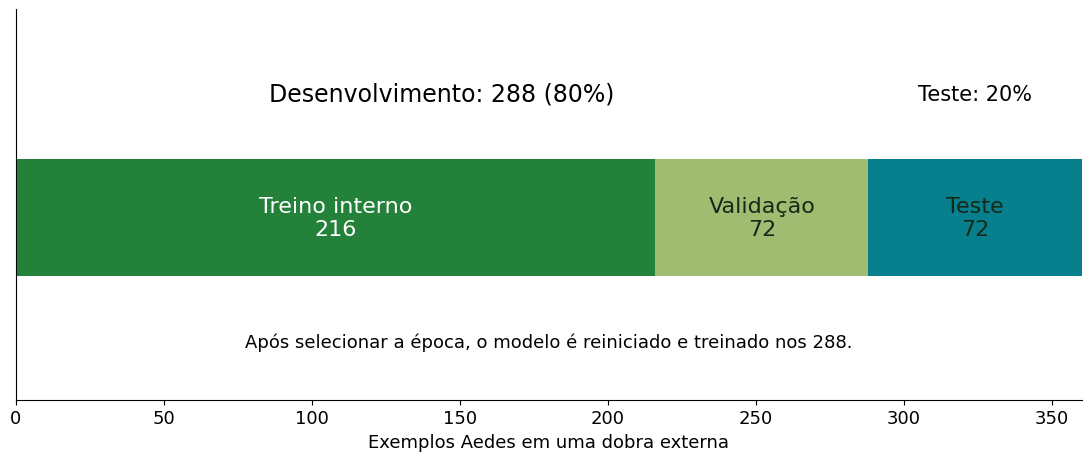

In [4]:
display(pd.DataFrame(PATTERN_REFERENCE["folds"]))
fig = pattern_figure(PATTERN_REFERENCE, "split")
plt.show()


## 4. Do áudio ao espectrograma Mel
**FFT** mostra a intensidade das frequências de um trecho. **STFT** repete essa análise em pequenos trechos sucessivos; o espectrograma mostra tempo, frequência e intensidade. **Mel** agrupa frequências em bandas, criando uma entrada compacta.

Torres disponibiliza 300 espectrogramas de 32 bandas, mas somente dois WAVs. Para compatibilizar as fontes, esta rodada usa um frontend comum **aproximado**: 16 bandas HTK abaixo de 4 kHz e 179 instantes reais. A reamostragem dos áudios originais de 8 para 48 kHz compatibiliza o cálculo, sem criar informação de alta frequência. FFT de 1.024 amostras, janela Hann e avanço de 256 amostras a 48 kHz; retiramos duas bordas e usamos o centro real, sem preenchimento nem repetição.

O gráfico abaixo vem de uma janela real Dryad. A sequência foi arredondada apenas no retrato didático, não nos dados de treino.


Fonte: dryad · forma: [179, 16]


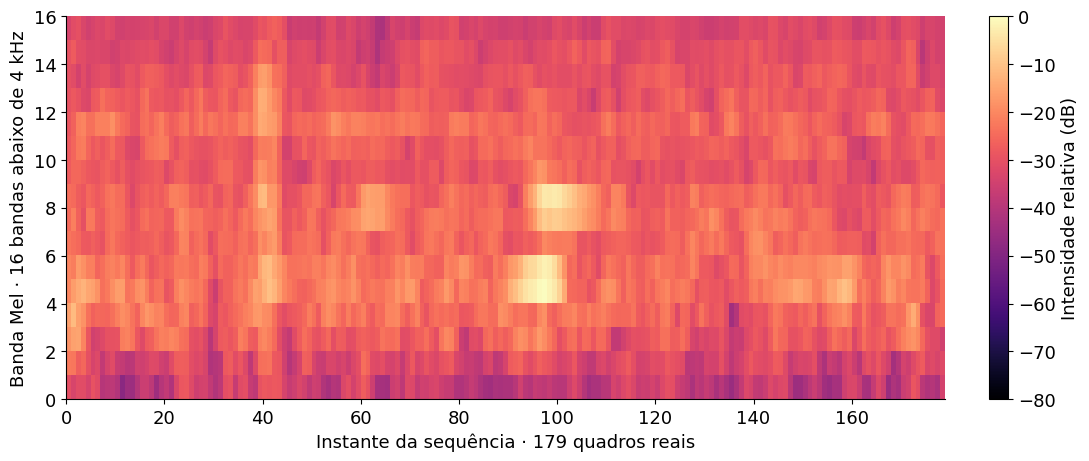

In [5]:
example = PATTERN_REFERENCE["example"]
print("Fonte:", example["source"], "· forma:", example["shape"])
fig = pattern_figure(PATTERN_REFERENCE, "mel")
plt.show()


## 5. O que cada modelo aprende?
| Técnica | O que recebe | Como reconhece padrões | Por que testar |
|---|---|---|---|
| CNN 2D | Espectrograma 179 × 16 | Filtros aprendem padrões locais de tempo/frequência | Conservar a localização de padrões espectrais |
| MLP | 80 atributos por janela | Camadas densas combinam atributos | Rede compacta, sem recorrência |
| SVM RBF | 80 atributos | Fronteira não linear entre classes | Comparação com outro princípio de classificação |
| Extra Trees | 80 atributos | Votação/combinação de 250 árvores aleatórias | Capturar interações sem uma rede neural |
| HistGradientBoosting | 80 atributos | Árvores sucessivas corrigem erros | Referência de boosting para atributos tabulares |

Os 80 atributos são média, desvio padrão e percentis 10, 50 e 90 das 16 bandas, ao longo do tempo. A CNN conserva a posição das frequências e reduz a dimensão temporal. A MLP tem camadas de 128 e 64 unidades. A CNN tem blocos de 16, 32 e 64 canais e uma camada densa de 128 unidades.

LSTM também permite classificação. A troca de prioridade para CNN/MLP é uma decisão experimental; não significa que LSTM só possa prever valores futuros.


## 6. Como o treino foi equilibrado e otimizado?
Há 300 exemplos Torres e 60 grupos Aedes originais. **Balancear somente as classes pode dar muita influência a Torres.** O treino atual atribui massa igual às células fonte/classe observadas no treino. A fonte serve ao balanceamento e à avaliação; não é uma entrada do classificador.

Também amortecemos o peso de gravações com muitas janelas usando `min(n_janelas, 60) ** -0.5`, normalizado por célula fonte/classe. As redes usam amostragem ponderada de janelas reais, sem criação de exemplos sintéticos.

Normalização é estimada somente no treino. Para as redes: AdamW, taxa 0,0006, regularização de pesos 0,001, dropout, lotes de 256, limite de gradiente 3, até 30 épocas e parada após cinco épocas sem melhora. SVM compara C=0,1/1/10; Extra Trees compara folhas mínimas de 2/8; HistGB compara regularização 1/5. Não houve uma ablação que isolasse o ganho causal de cada ajuste.

A **época** é escolhida pela perda de validação em grupos, equilibrada por fonte/classe. A **técnica/parâmetros** são escolhidos pela média das sensibilidades das células fonte/classe na validação. O teste não escolhe o modelo.


,Modelo,Dobra,Época escolhida,Épocas observadas
0,CNN 2D,0,2,7
1,CNN 2D,1,3,8
2,CNN 2D,2,4,9
3,CNN 2D,3,3,8
4,CNN 2D,4,7,12
5,MLP,0,15,20
6,MLP,1,18,23
7,MLP,2,6,11
8,MLP,3,13,18
9,MLP,4,12,17


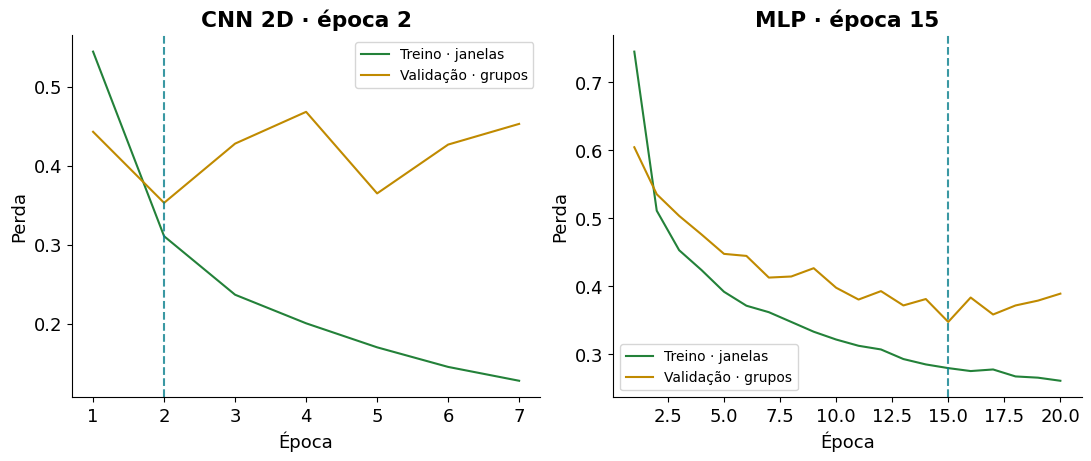

In [6]:
epoch_rows = []
for name in ["cnn", "mlp"]:
    for fold, data in PATTERN_REFERENCE["neural_histories"][name].items():
        epoch_rows.append({"Modelo": PATTERN_NAMES[name], "Dobra": int(fold),
                           "Época escolhida": data["selection"]["best_epoch"],
                           "Épocas observadas": len(data["history"])})
display(pd.DataFrame(epoch_rows))
fig = pattern_figure(PATTERN_REFERENCE, "learning")
plt.show()


## 7. Como juntamos as janelas e calculamos as métricas?
O classificador produz três escores por janela. Combinamos os escores por grupo, dando mais peso às janelas com evidência de mosquito: `peso = (1 - escore_ruído) ** 1.5`. A decisão primária escolhe a classe com maior escore agregado; não é voto majoritário.

**Acurácia** = acertos em todas as classes ÷ total de grupos. **Sensibilidade Aedes** = Aedes reconhecidos ÷ Aedes reais. **Falso positivo em ruído/outros** = negativos daquela classe classificados como Aedes ÷ total daquela classe. Esses denominadores são diferentes.

Nos gráficos seguintes, a regra primária é sempre a mesma: maior escore. O SVM usa escores de margem normalizados para agregar; esses escores não são probabilidades calibradas.


,Acurácia (%),Sensibilidade Aedes (%),Aedes detectados,Ruído → Aedes (%),Outro → Aedes (%)
Modelo,,,,,
CNN 2D,89.52,96.39,347/360,2.11,5.16
MLP,88.18,98.61,355/360,4.69,10.12
SVM RBF,79.10,96.11,346/360,7.04,20.14
Extra Trees,87.35,93.33,336/360,1.64,7.24
HistGB,87.57,94.72,341/360,1.41,7.44


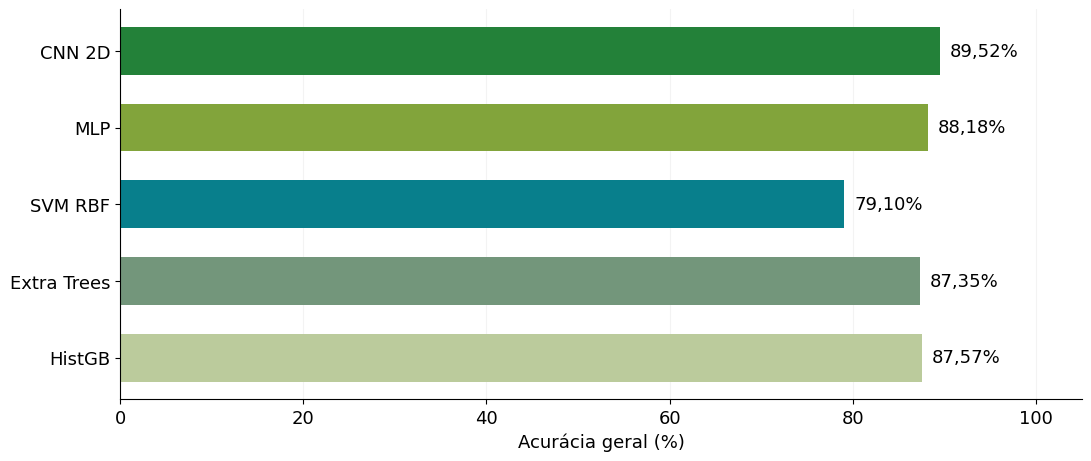

In [7]:
pattern_rows = []
for name in PATTERN_MODELS:
    v = PATTERN_REFERENCE["metrics"][name]["argmax"]["all"]
    pattern_rows.append({"Modelo":PATTERN_NAMES[name], "Acurácia (%)":100*v["accuracy"],
        "Sensibilidade Aedes (%)":100*v["aedes_recall"], "Aedes detectados":f'{v["aedes_tp"]}/{v["aedes_total"]}',
        "Ruído → Aedes (%)":100*v["noise_fpr"], "Outro → Aedes (%)":100*v["other_fpr"]})
pattern_results = pd.DataFrame(pattern_rows).set_index("Modelo")
display(pattern_results.round(2))
fig = pattern_figure(PATTERN_REFERENCE, "accuracy")
plt.show()


## 8. Acurácia de teste por dataset
Cada célula considera todas as classes presentes naquela fonte. Dryad e HumBug contêm vários tipos de mosquito/fundo; Torres contém somente Aedes; ESC-50 contém somente ruído. **100% em Torres não significa 100% nas três classes.**

As contagens são acumuladas nas cinco dobras: cada um dos 613 grupos Dryad, 592 HumBug, 300 exemplos Torres e 289 ESC-50 foi testado uma vez.


,CNN 2D,MLP,SVM RBF,Extra Trees,HistGB
dryad,91.68,88.09,69.82,84.83,85.32
humbug,88.85,84.29,77.87,88.01,89.02
torres,99.33,100.00,98.67,96.67,98.67
esc50,76.12,84.08,80.97,81.66,77.85


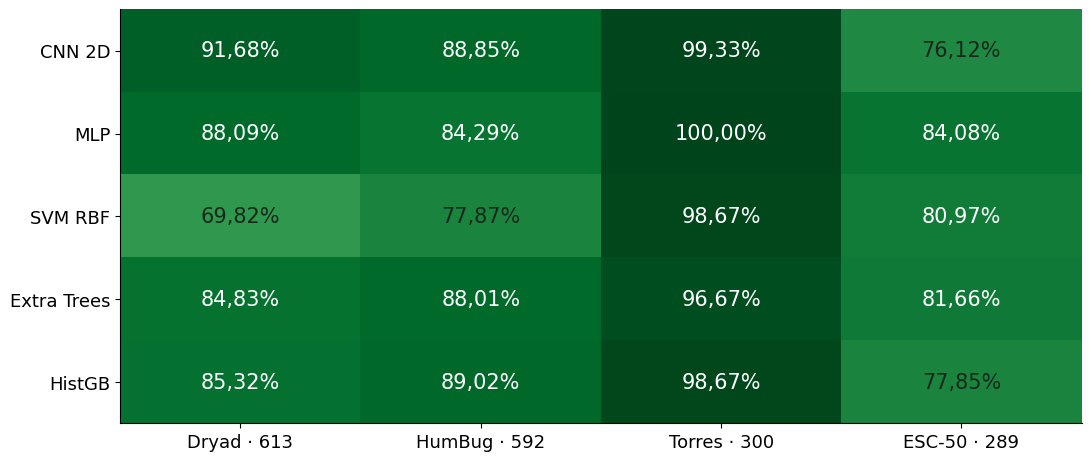

In [8]:
dataset_accuracy = pd.DataFrame({PATTERN_NAMES[n]: {s:100*PATTERN_REFERENCE["metrics"][n]["argmax"][s]["accuracy"]
    for s in ["dryad","humbug","torres","esc50"]} for n in PATTERN_MODELS})
display(dataset_accuracy.round(2))
fig = pattern_figure(PATTERN_REFERENCE, "datasets")
plt.show()


## 9. Quantos Aedes foram reconhecidos em cada fonte?
Aqui o denominador é somente Aedes: Dryad **20**, HumBug **40** e Torres **300**. Mantemos as fontes separadas para que o volume de Torres não esconda os resultados nos 60 grupos originais.


,CNN 2D,MLP
Fonte,,
dryad,19/20 (95.00%),19/20 (95.00%)
humbug,30/40 (75.00%),36/40 (90.00%)
torres,298/300 (99.33%),300/300 (100.00%)


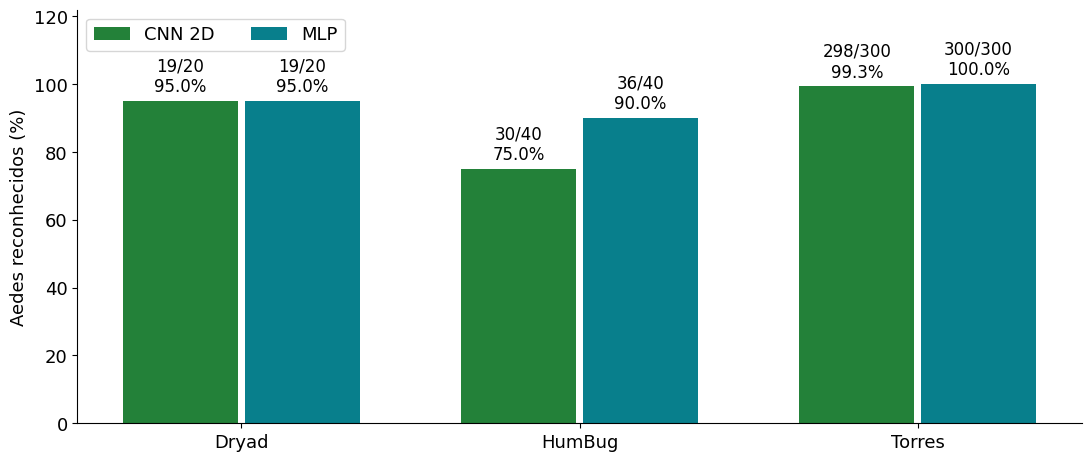

In [9]:
aedes_rows = []
for source in ["dryad","humbug","torres"]:
    row={"Fonte":source}
    for name in ["cnn","mlp"]:
        v=PATTERN_REFERENCE["metrics"][name]["argmax"][source]
        row[PATTERN_NAMES[name]]=f'{v["aedes_tp"]}/{v["aedes_total"]} ({100*v["aedes_recall"]:.2f}%)'
    aedes_rows.append(row)
display(pd.DataFrame(aedes_rows).set_index("Fonte"))
fig = pattern_figure(PATTERN_REFERENCE, "aedes")
plt.show()


## 10. Ler os erros junto aos acertos
A MLP recupera mais Aedes originais, mas emite mais falsos alarmes. A CNN apresenta maior acurácia geral nesta comparação e menos falsos alarmes que a MLP. São observações de teste, não justificativa para selecionar retrospectivamente uma técnica e tratá-la como se já tivesse sido escolhida antes do teste.

Na matriz, as linhas representam a classe verdadeira e as colunas a previsão. A diagonal contém acertos; as outras células mostram quais classes foram confundidas.


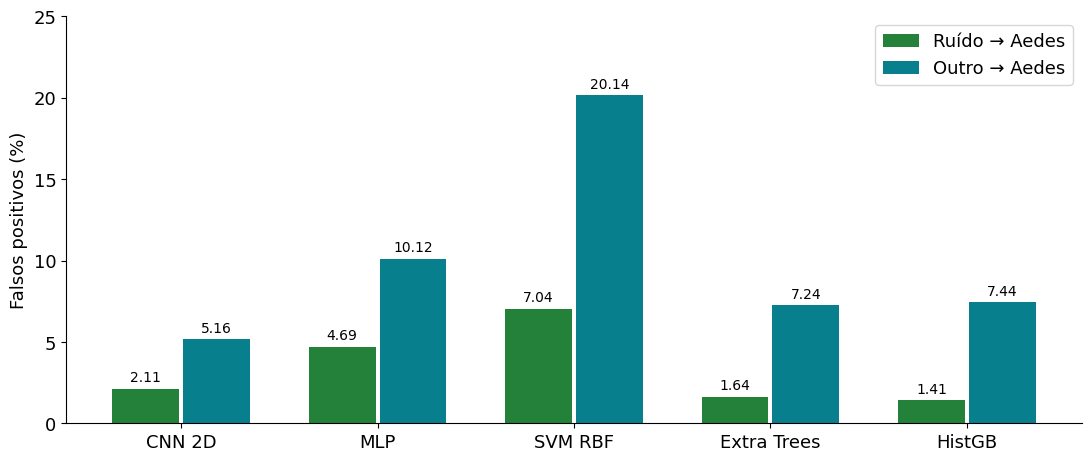

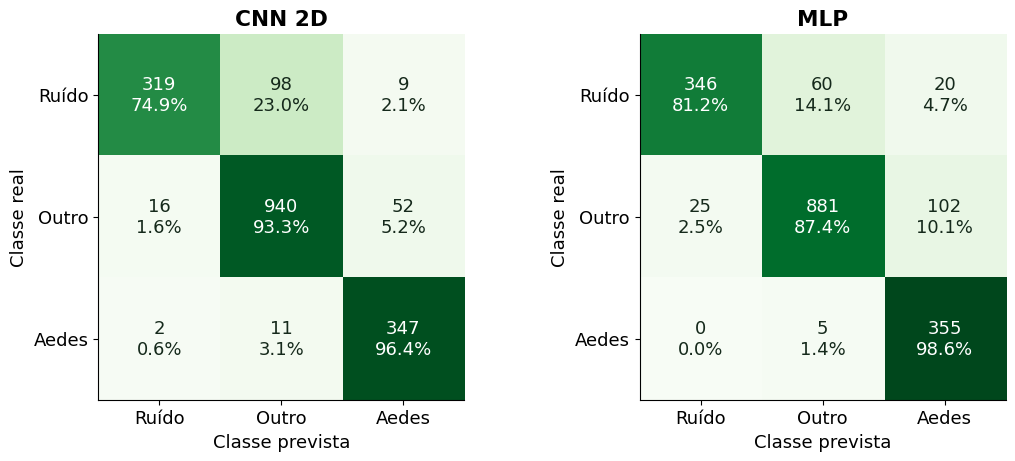

In [10]:
fig = pattern_figure(PATTERN_REFERENCE, "false_positives")
plt.show()
fig = pattern_figure(PATTERN_REFERENCE, "confusion")
plt.show()


## 11. O efeito de ajustar os limiares
A regra alternativa usa limiares definidos na validação para emitir o alerta de Aedes. Ela pode reduzir falsos alarmes e deixar passar mais Aedes. A rede treinada é a mesma; muda a regra de decisão.

O gráfico usa a sensibilidade **nos 60 Aedes originais**, ao lado dos falsos alarmes. Não combinamos a acurácia de uma regra com a sensibilidade de outra. A regra primária do experimento foi definida antes do teste como maior escore.


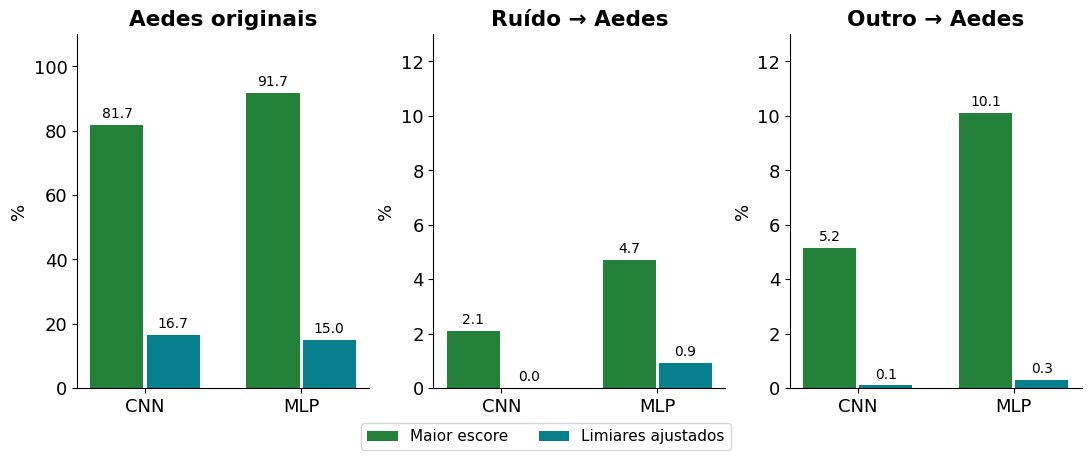

In [11]:
fig = pattern_figure(PATTERN_REFERENCE, "rules")
plt.show()


## 12. Qual modelo foi salvo para aplicação?
O candidato final foi escolhido pela **média das validações internas**, não pela maior acurácia de teste. A MLP foi selecionada por esse critério, e o ajuste final usou 13 épocas nos 1.794 grupos/exemplos. Esse modelo treinado com todos os dados não possui um novo teste independente.

A linha `validation_selected` das métricas corresponde a outra pergunta: em cada dobra, qual foi o resultado do modelo escolhido pela validação daquela dobra? Ela não escolhe o melhor resultado de teste de cada dobra.


In [12]:
final_info=PATTERN_REFERENCE["final_model"]
display(pd.Series(final_info["mean_inner_validation_scores"],name="Pontuação média da validação"))
print("Candidato final:",PATTERN_NAMES[final_info["model"]],"· épocas:",final_info["epochs"])
print("Pesos locais:",PATTERN_RUN / "final")
selected=PATTERN_REFERENCE["metrics"]["validation_selected"]["argmax"]["all"]
print(f'Seleção interna por dobra: {selected["correct"]}/{selected["n"]} acertos ({100*selected["accuracy"]:.2f}%).')


svm_rbf        0.818914
extra_trees    0.829121
histgb         0.785854
mlp            0.850778
cnn            0.828047
Name: Pontuação média da validação, dtype: float64

Candidato final: MLP · épocas: 13
Pesos locais: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/results/pattern_classifiers_2026_10_15/final
Seleção interna por dobra: 1583/1794 acertos (88.24%).


## 13. Aplicar o modelo salvo a um áudio WAV
Defina `PATTERN_AUDIO_PATH` no início. Esta célula exige os pesos, normalizador e manifesto locais em `PATTERN_RUN/final/`; o clone enxuto do Git não contém os pesos. O código verifica os hashes, prepara janelas reais, calcula a mesma representação e agrega os escores.

Um WAV real de Torres já foi usado para verificar a execução da inferência. Isso é um teste de funcionamento do código, não uma nova estimativa independente de acurácia nem identificação de infecção. Os escores não representam probabilidade de campo calibrada.


In [13]:
if PATTERN_AUDIO_PATH is None:
    print("Defina PATTERN_AUDIO_PATH com um WAV para executar a inferência local.")
    print("Exemplo real já executado:", PATTERN_REFERENCE["real_wav_smoke_test"]["prediction"])
else:
    from predict_pattern import predict as predict_pattern_wav
    display(predict_pattern_wav(PATTERN_RUN / "final",Path(PATTERN_AUDIO_PATH)))


Defina PATTERN_AUDIO_PATH com um WAV para executar a inferência local.
Exemplo real já executado: aedes_aegypti


## 14. Reproduzir um novo treinamento, opcionalmente
Ative `RUN_PATTERN_TRAINING` somente após preparar os dados reais locais. O JSON didático sozinho não é suficiente para treinar.

O comando usa o manifesto de 42.329 linhas, atributos 80D, cache 179×16 e hashes de origem. Uma nova pasta de saída é criada. Copiamos a referência de entrada para a nova rodada e registramos o estado atual dos documentos, sem alterar os protocolos nem os pesos da rodada anterior.

O treino completo executa SVM, Extra Trees, HistGB, MLP e CNN nas mesmas cinco dobras. Ao terminar, gera predições OOF, métricas, seleção interna, curvas e pesos por dobra. Abrir este caderno não executa essa etapa.


In [14]:
PATTERN_NEW_RUN=None
if RUN_PATTERN_TRAINING:
    import hashlib,shutil,subprocess
    for item in [PATTERN_INPUTS/"segments.csv.gz",PATTERN_INPUTS/"classical_features.npy",
                 PATTERN_INPUTS/"feature_cache.json",PATTERN_INPUTS/"protocol.json",PATTERN_SEQUENCES]:
        if not item.is_file():raise FileNotFoundError(f"Entrada real ausente: {item}")
    tag=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    inputs=ROOT/"results"/f"pattern_inputs_{tag}"
    inputs.mkdir(parents=True,exist_ok=False)
    for name in ["segments.csv.gz","classical_features.npy","feature_cache.json"]:
        shutil.copy2(PATTERN_INPUTS/name,inputs/name)
    prior_protocol=json.loads((PATTERN_INPUTS/"protocol.json").read_text())
    current_protection={name:hashlib.sha256((ROOT/name).read_bytes()).hexdigest()
                        for name in prior_protocol["protected_sha256"]}
    (inputs/"protocol.json").write_text(json.dumps({"protected_sha256":current_protection},indent=2))
    PATTERN_NEW_RUN=ROOT/"results"/f"pattern_notebook_{tag}"
    subprocess.run([sys.executable,str(ROOT/"train_pattern_classifiers.py"),"--reference",str(inputs),
        "--sequences",str(PATTERN_SEQUENCES),"--out",str(PATTERN_NEW_RUN)],cwd=ROOT,check=True)
else:
    print("Treinamento desativado. Resultados mostrados acima são da rodada já concluída.")


Treinamento desativado. Resultados mostrados acima são da rodada já concluída.


## 15. Verificar os modelos preservando a revisão didática
O verificador recarrega os modelos, reproduz as predições, confere partições, cobertura, normalizadores e seleção por validação. A rodada original foi auditada antes desta atualização do notebook.

Esta revisão do documento foi autorizada depois do experimento. Um recibo registra o hash anterior e o novo somente para o notebook; **não permite mudanças em pesos, dados ou arquivos científicos protegidos**. O verificador salva um recibo adicional, preservando a auditoria original.


In [15]:
if RUN_PATTERN_VERIFY:
    import subprocess
    revision=ROOT/"output/pattern_slides_2026_10_16/document_revision.json"
    if not revision.is_file():raise FileNotFoundError("Recibo local da revisão documental ausente.")
    subprocess.run([sys.executable,str(ROOT/"verify_pattern_classifiers.py"),"--out",str(PATTERN_RUN),
        "--reference",str(PATTERN_INPUTS),"--sequences",str(PATTERN_SEQUENCES),
        "--document-revision",str(revision)],cwd=ROOT,check=True)
else:
    print("Verificação longa desativada. Auditoria original: 25 modelos principais + 8 testes por fonte reproduzidos.")


Verificação longa desativada. Auditoria original: 25 modelos principais + 8 testes por fonte reproduzidos.


## 16. Coleta própria com o protótipo
As fotos da montagem e da placa estão na apresentação. A próxima coleta deverá registrar WAV real, espécie confirmada, indivíduo quando conhecido, sessão, distância, temperatura, dispositivo e ruído de fundo. Incluir Aedes, outros mosquitos e ausência de mosquito.

A proposta é adquirir e organizar dados para treino/teste com sessões novas. Não foi demonstrada execução destas redes na placa. As etapas de aquisição padronizada e validação do protótipo continuam futuras.


## 17. Até onde os resultados se mantêm?
O teste principal mistura fontes no desenvolvimento e no teste, com grupos separados. Para testar uma condição mais difícil, excluímos uma fonte inteira e blocos PCM coincidentes do desenvolvimento. CNN e MLP foram predefinidas para essa análise, e o treino usa somente as outras fontes.

O resultado cai bastante: o bom desempenho na mistura não demonstrou transferência consistente para uma origem ausente do treino. Este teste é exploratório e retrospectivo, não uma nova campanha cega.


,Fonte excluída,Modelo,Acurácia (%),Aedes detectados,Ruído → Aedes,Outro → Aedes
0,dryad,MLP,26.26,1/20,0/44,42/549
1,dryad,CNN 2D,35.89,0/20,0/44,8/549
2,esc50,MLP,50.17,0/0,38/289,0/0
3,esc50,CNN 2D,52.25,0/0,15/289,0/0
4,humbug,MLP,36.49,2/40,0/93,52/459
5,humbug,CNN 2D,27.53,5/40,0/93,67/459
6,torres,MLP,2.67,8/300,0/0,0/0
7,torres,CNN 2D,0.67,2/300,0/0,0/0


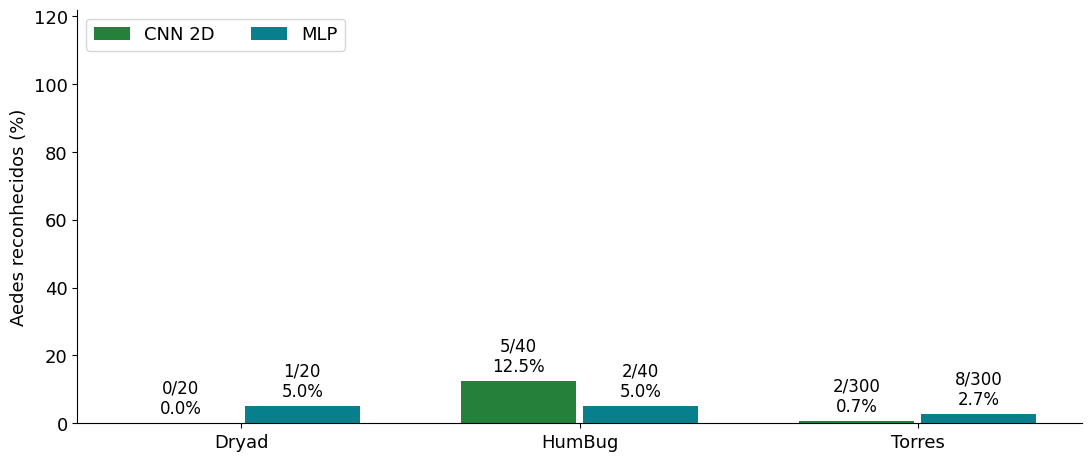

In [16]:
holdout_rows=[]
for source,models in PATTERN_REFERENCE["source_holdout"].items():
    for name,scores in models.items():
        v=scores["argmax"]
        holdout_rows.append({"Fonte excluída":source,"Modelo":PATTERN_NAMES[name],
            "Acurácia (%)":100*v["accuracy"],"Aedes detectados":f'{v["aedes_tp"]}/{v["aedes_total"]}',
            "Ruído → Aedes":f'{v["noise_fp"]}/{v["noise_total"]}',"Outro → Aedes":f'{v["other_fp"]}/{v["other_total"]}'})
display(pd.DataFrame(holdout_rows).round(2))
fig=pattern_figure(PATTERN_REFERENCE,"holdout")
plt.show()


## 18. Interpretação final e fontes
A CNN obteve 89,52% de acurácia geral e detectou 49/60 Aedes originais; a MLP detectou 55/60, com mais falsos alarmes. Os números são úteis para o corpus combinado. A transferência entre fontes ainda precisa melhorar.

Não é possível atribuir os resultados somente à arquitetura: também mudaram os dados, a representação e o balanceamento. A cascata antiga de 90,03% usou outro corpus/protocolo e fica no apêndice, sem comparação direta como um ranking único. Grupos não comprovam indivíduos biológicos independentes; o frontend Torres é aproximado.

Fontes: métricas e verificações com SHA-256 no JSON versionado; [CNN para espectrogramas](https://arxiv.org/abs/1706.09559); [SVM](https://scikit-learn.org/stable/modules/svm); [Extra Trees](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html); [implementação/dados de Torres](https://github.com/NakanoMariko/Dengue-Infected-Mosquito-Detection).


# Apêndice — experimentos anteriores com 1.494 grupos
**Daqui em diante, as contagens de 60 Aedes e os resultados de cascata/LSTM/Bi-LSTM pertencem ao corpus anterior.** Não substituem nem compõem o novo teste acima. Estes conteúdos e controles foram preservados para estudo e reexecução opcional.


## 1. O que este experimento aprende

Cada linha da tabela corresponde a uma janela de áudio já transformada em descritores acústicos. O modelo combina regressão logística e HistGradientBoosting. O problema tem três classes: silêncio/ruído sem mosquito, outros mosquitos e *Aedes aegypti*.

A pergunta não é apenas “quantas janelas acertou?”. Janelas do mesmo arquivo se parecem. Por isso, a unidade principal do teste é o **grupo de gravação**, e blocos identificados como o mesmo áudio PCM são mantidos na mesma partição. Isso reduz vazamento entre treino e teste.

O pipeline usa validação cruzada aninhada: as dobras internas escolhem configuração e regras de decisão; a dobra externa estima desempenho em grupos que não participaram dessas escolhas. Depois do teste, um modelo final é ajustado em todos os dados de desenvolvimento para permitir a aplicação a uma gravação. Esse modelo final não tem um teste independente próprio.

Além da cascata, duas redes profundas analisam o áudio como uma sequência. A **LSTM** usa o contexto dos instantes anteriores; a **Bi-LSTM** lê o trecho nos dois sentidos. Elas recebem bandas mel, não os descritores das árvores. As três abordagens conservam a mesma tarefa e as mesmas dobras externas na comparação.

## 2. Preparar o ambiente e localizar o projeto

Na raiz do repositório, instale as dependências listadas em `requirements.txt`. Os arquivos de áudio e o cache de descritores não são copiados para o GitHub. O treino completo exige que eles estejam disponíveis localmente nos caminhos exibidos na próxima célula.

Os metadados compactos das janelas e os vínculos entre gravações acompanham o repositório em `data/metadata/`. O cache `features.npy` deve ter uma linha por janela do manifesto e ser preparado a partir dos áudios originais com o frontend descrito neste projeto.

## 3. Conferir as entradas antes do treino

O manifesto contém rótulos, grupo de gravação, domínio, posição temporal e índice da janela. O mapa de colisões reúne gravações que compartilham a mesma identidade PCM conhecida. O cache é uma matriz numérica alinhada linha a linha ao manifesto.

**Por que o cache não está no Git?** Ele é um artefato reconstruível e os áudios originais são volumosos. Para manter o repositório leve, o notebook interrompe o treino com uma mensagem clara se o cache local estiver ausente; os metadados necessários para interpretar/alocar as linhas continuam versionados.

In [17]:
required_inputs = {
    "manifesto de janelas": SEGMENTS,
    "cache de descritores": FEATURES,
    "mapa de colisões PCM": KNOWN_MAP,
}
missing = [f"{name}: {path}" for name, path in required_inputs.items() if not path.is_file()]
if RUN_NEW_TRAINING and missing:
    raise FileNotFoundError("Para treinar, providencie estas entradas locais:\n- " + "\n- ".join(missing))

if SEGMENTS.is_file():
    manifest = pd.read_csv(SEGMENTS, low_memory=False)
    print(f"Janelas no manifesto: {len(manifest):,}")
    display(manifest[[c for c in ["path", "label", "group", "domain", "start_s", "bucket"] if c in manifest]].head())
if FEATURES.is_file():
    feature_shape = np.load(FEATURES, mmap_mode="r").shape
    print("Formato do cache:", feature_shape)
if KNOWN_MAP.is_file():
    print("Mapa de colisões disponível:", KNOWN_MAP.stat().st_size, "bytes")

Janelas no manifesto: 49,713


,path,label,group,domain,start_s,bucket
0,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,0.0,long
1,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,1.0,long
2,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,2.0,long
3,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,3.0,long
4,data/raw/Aedes aegypti/Aedes aegypti/Auburn_T2...,Aedes aegypti,78e0631c91faf904c84f8569148778099be383553af71a...,dryad,4.0,long


Formato do cache: (49713, 138)
Mapa de colisões disponível: 176978 bytes


## 4. Um resultado de referência — sem retreino

Este retrato foi calculado a partir da avaliação OOF concluída em 14/10/2026. O caderno guarda os números essenciais para leitura e para desenhar a matriz de confusão; os milhares de arquivos intermediários da execução foram retirados do repositório.

A linha de cada classe na matriz é a classe real; a coluna é a previsão. O modelo de referência é a cascata com porta de atividade e agregação temporal. Acurácia global pode esconder erros importantes em classes menores; por isso também observamos precisão e sensibilidade de *Aedes* e falsos positivos por classe.

In [18]:
REFERENCE = {
  "run_id": "ternary_verified_2026_10_14_corrections",
  "model": "activity_gated_log_odds_cascade_event",
  "evaluation_unit": "group",
  "total_groups": 1494,
  "groups_per_class": {
    "no_mosquito": 426,
    "other_mosquito": 1008,
    "aedes_aegypti": 60
  },
  "windows_retained": 42029,
  "training_windows_by_class": {
    "no_mosquito": 8658,
    "other_mosquito": 31205,
    "aedes_aegypti": 2166
  },
  "accuracy": 0.9002677376171352,
  "balanced_accuracy": 0.8367221849616215,
  "aedes_recall": 0.7833333333333333,
  "aedes_precision": 0.6714285714285714,
  "noise_to_aedes_fpr": 0.0,
  "other_to_aedes_fpr": 0.022817460317460316,
  "noise_to_any_mosquito_fpr": 0.23943661971830985,
  "counts": {
    "aedes_tp": 47,
    "aedes_total": 60,
    "noise_fp_to_aedes": 0,
    "noise_total": 426,
    "other_fp_to_aedes": 23,
    "other_total": 1008,
    "noise_fp_to_any_mosquito": 102
  },
  "confusion_matrix": [
    [
      324,
      102,
      0
    ],
    [
      11,
      974,
      23
    ],
    [
      0,
      13,
      47
    ]
  ],
  "classes": [
    "no_mosquito",
    "other_mosquito",
    "aedes_aegypti"
  ]
}

reference_table = pd.DataFrame([
    ("Grupos avaliados (unidade principal)", REFERENCE["total_groups"]),
    ("Janelas retidas para desenvolvimento", REFERENCE["windows_retained"]),
    ("Acurácia por grupo", f"{REFERENCE['accuracy']:.1%}"),
    ("Acurácia balanceada por grupo", f"{REFERENCE['balanced_accuracy']:.1%}"),
    ("Sensibilidade de Aedes", f"{REFERENCE['aedes_recall']:.1%} ({REFERENCE['counts']['aedes_tp']}/{REFERENCE['counts']['aedes_total']})"),
    ("Precisão de Aedes", f"{REFERENCE['aedes_precision']:.1%}"),
    ("Ruído classificado como Aedes", f"{REFERENCE['counts']['noise_fp_to_aedes']}/{REFERENCE['counts']['noise_total']}"),
    ("Outros mosquitos classificados como Aedes", f"{REFERENCE['counts']['other_fp_to_aedes']}/{REFERENCE['counts']['other_total']}"),
    ("Ruído classificado como algum mosquito", f"{REFERENCE['counts']['noise_fp_to_any_mosquito']}/{REFERENCE['counts']['noise_total']}"),
], columns=["Medida", "Resultado"])
display(reference_table)
print("Contagem de grupos por classe:", REFERENCE["groups_per_class"])

,Medida,Resultado
0,Grupos avaliados (unidade principal),1494
1,Janelas retidas para desenvolvimento,42029
2,Acurácia por grupo,90.0%
3,Acurácia balanceada por grupo,83.7%
4,Sensibilidade de Aedes,78.3% (47/60)
5,Precisão de Aedes,67.1%
6,Ruído classificado como Aedes,0/426
7,Outros mosquitos classificados como Aedes,23/1008
8,Ruído classificado como algum mosquito,102/426


Contagem de grupos por classe: {'no_mosquito': 426, 'other_mosquito': 1008, 'aedes_aegypti': 60}


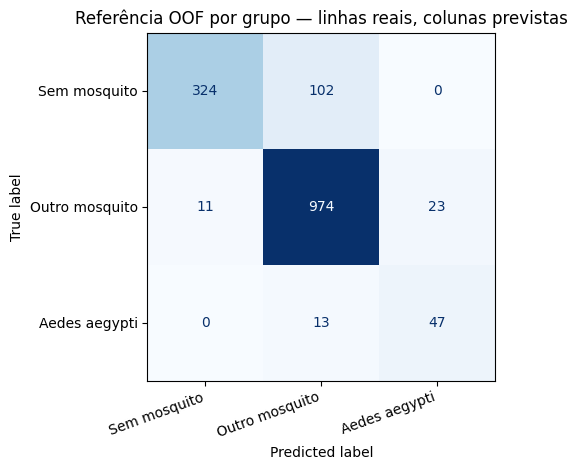

In [19]:
labels = ["Sem mosquito", "Outro mosquito", "Aedes aegypti"]
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=np.asarray(REFERENCE["confusion_matrix"]),
    display_labels=labels,
)
display_cm.plot(cmap="Blues", values_format="d", colorbar=False)
plt.title("Referência OOF por grupo — linhas reais, colunas previstas")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

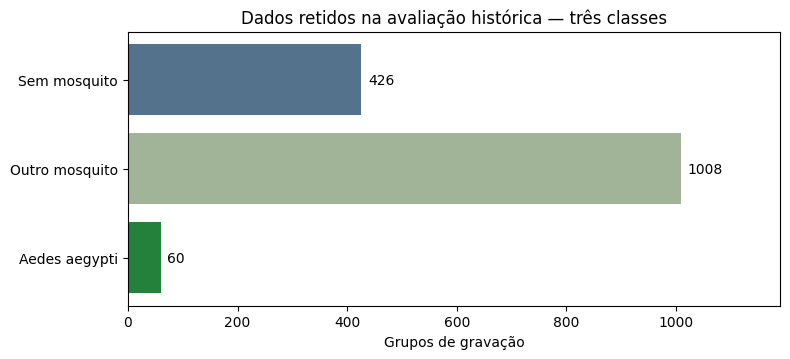

In [20]:
counts = REFERENCE["groups_per_class"]
fig, ax = plt.subplots(figsize=(8, 3.7))
values = [counts[name] for name in CLASS_NAMES]
bars = ax.barh(labels, values, color=["#54728c", "#a2b497", "#24813b"])
ax.invert_yaxis()
ax.set_xlabel("Grupos de gravação")
ax.set_title("Dados retidos na avaliação histórica — três classes")
ax.set_xlim(0, max(values) * 1.18)
for bar, value in zip(bars, values):
    ax.text(value + 12, bar.get_y() + bar.get_height()/2, str(value), va="center")
plt.tight_layout()
plt.show()

### Um exemplo real: sinal, FFT e sequência mel

Quando o cache local está disponível, esta célula usa uma janela real de Aedes do Dryad. O primeiro gráfico mostra a amplitude no tempo; a FFT mostra suas frequências; o espectrograma mel mostra a intensidade das64 bandas em55 instantes. O rótulo vem do dataset, não de uma previsão. As imagens ficam salvas no notebook executado; para recalculá-las é necessário o cache correspondente.

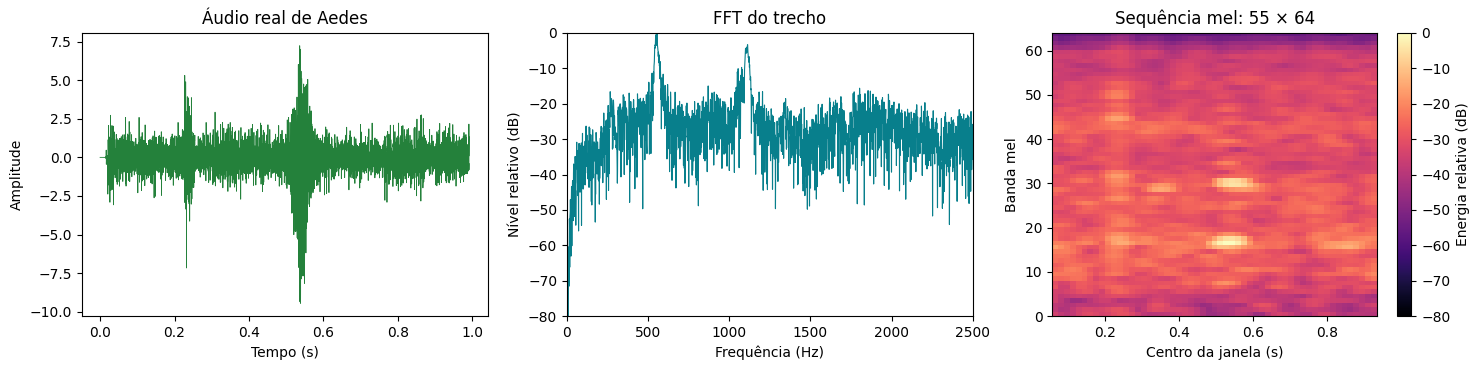

Exemplo real: data/raw/Aedes aegypti/Aedes aegypti/Auburn_T209/Voice0121 AEGY ui.wav


In [21]:
wave_cache_path = ROOT / "data/cache/reliability_2026_10_01/long_8k.npy"
if SEGMENTS.is_file() and wave_cache_path.is_file():
    import torch
    from train_ternary_lstm import frontend as neural_frontend
    examples = manifest.loc[manifest.label.eq("Aedes aegypti") & manifest.domain.eq("dryad")
                            & manifest.bucket.eq("long") & manifest.quality_ok.isin([True, "True", 1])]
    example = examples.iloc[0]
    cache = np.load(wave_cache_path, mmap_mode="r")
    wave = np.array(cache[int(example.wave_index)], dtype="float32")
    sample_rate = 8000
    seconds = np.arange(len(wave)) / sample_rate
    spectrum = np.abs(np.fft.rfft((wave - wave.mean()) * np.hanning(len(wave))))
    spectrum_db = 20 * np.log10(np.maximum(spectrum / max(spectrum.max(), 1e-12), 1e-8))
    with torch.inference_mode():
        mel = neural_frontend()(torch.from_numpy(wave[None])).numpy()[0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    axes[0].plot(seconds, wave, color="#24813b", linewidth=.6)
    axes[0].set(title="Áudio real de Aedes", xlabel="Tempo (s)", ylabel="Amplitude")
    axes[1].plot(np.fft.rfftfreq(len(wave), 1/sample_rate), spectrum_db, color="#087f8c", linewidth=.8)
    axes[1].set(title="FFT do trecho", xlabel="Frequência (Hz)", ylabel="Nível relativo (dB)", xlim=(0, 2500), ylim=(-80, 0))
    image = axes[2].imshow(mel.T, origin="lower", aspect="auto", cmap="magma",
                           extent=[(512-64)/sample_rate, (512+128*(mel.shape[0]-1)+64)/sample_rate, 0, 64], vmin=-80, vmax=0)
    axes[2].set(title="Sequência mel: 55 × 64", xlabel="Centro da janela (s)", ylabel="Banda mel")
    fig.colorbar(image, ax=axes[2], label="Energia relativa (dB)")
    plt.tight_layout()
    plt.show()
    print("Exemplo real:", example.path)
else:
    print("Cache de áudio ausente. As demais figuras usam as referências compactas versionadas.")

## 5. Como funciona o treino e o teste

A função `train()` prepara uma rodada imutável, audita identidades de áudio, separa grupos por blocos PCM e congela os modelos antes de qualquer previsão na dobra externa. A função `evaluate()` então prevê cada grupo externo uma única vez e calcula métricas por evento/gravação.

A política principal da referência detectou 47 dos 60 grupos *Aedes* (78,3%) e não emitiu *Aedes* para os 426 grupos de ruído. Ainda classificou 23 dos 1.008 grupos de outros mosquitos como *Aedes*. A meta amostral definida para essa confusão era no máximo 19; portanto, **o critério não foi atingido**. Além disso, 102/426 grupos de ruído receberam alguma classe de mosquito.

Esses denominadores pertencem a este corpus. Grupos não são necessariamente indivíduos biológicos independentes e os intervalos binomiais não transformam essa avaliação em validação de campo.

### Iniciar uma rodada nova

O treino completo está desativado para que abrir o caderno não dispare uma execução longa. Depois de preparar os três arquivos listados na seção 3, altere `RUN_NEW_TRAINING = True` na célula de configuração e execute as células em ordem. O treino usa cinco dobras externas e quatro internas por padrão. Cada rodada recebe um nome UTC próprio e não substitui outra.

In [22]:
TRAINED_RUN = None
if RUN_NEW_TRAINING:
    from train_ternary_nested_models import train, evaluate

    run_id = datetime.now(timezone.utc).strftime("ternary_notebook_%Y%m%dT%H%M%SZ")
    TRAINED_RUN = ROOT / "results" / run_id
    train(TRAINED_RUN, threads=THREADS)
    evaluation = evaluate(TRAINED_RUN, threads=THREADS)
    print("Treino e teste concluídos em:", TRAINED_RUN)
else:
    print("Nenhum treino iniciado. A tabela e a matriz acima mostram a referência congelada.")

Nenhum treino iniciado. A tabela e a matriz acima mostram a referência congelada.


## 6. Ler os resultados da rodada nova

Ao habilitar o treino, esta célula carrega as métricas e previsões OOF recém-calculadas. A matriz mostra onde cada classe foi confundida. Examine principalmente falso positivo de *Aedes* em outros mosquitos e em ruído, além da cobertura: um sistema que se abstém muito pode apresentar boa precisão entre poucas emissões.

In [23]:
if TRAINED_RUN is not None:
    metrics_path = TRAINED_RUN / "event_level_metrics.json"
    predictions_path = TRAINED_RUN / "event_predictions.csv"
    if not metrics_path.is_file() or not predictions_path.is_file():
        raise FileNotFoundError("A etapa de avaliação não gerou os artefatos esperados.")
    fresh = json.loads(metrics_path.read_text())
    model_key = "activity_gated_log_odds_cascade_event"
    scores = fresh["models"][model_key]
    counts = scores["integer_counts"]
    display(pd.DataFrame([
        ("Execução", fresh["run_id"]),
        ("Acurácia", f"{scores['accuracy']:.1%}"),
        ("Acurácia balanceada", f"{scores['balanced_accuracy']:.1%}"),
        ("Sensibilidade Aedes", f"{counts['aedes_tp']}/{counts['aedes_total']}"),
        ("Ruído → Aedes", f"{counts['noise_fp_to_aedes']}/{counts['noise_total']}"),
        ("Outros → Aedes", f"{counts['other_fp_to_aedes']}/{counts['other_total']}"),
    ], columns=["Medida", "Resultado"]))
    event_table = pd.read_csv(predictions_path)
    matrix = pd.crosstab(event_table.true_label, event_table[model_key + "_pred"]).reindex(
        index=[0, 1, 2], columns=[0, 1, 2], fill_value=0
    ).to_numpy()
    ConfusionMatrixDisplay(matrix, display_labels=labels).plot(cmap="Blues", values_format="d", colorbar=False)
    plt.title("Rodada nova: teste OOF por grupo")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("A matriz acima corresponde à referência; ainda não houve treino nesta sessão.")

A matriz acima corresponde à referência; ainda não houve treino nesta sessão.


## 7. Aplicar o modelo a uma gravação WAV

A inferência divide o sinal em janelas reais, calcula os mesmos descritores usados no treino, verifica a integridade da rodada congelada e agrega a decisão ao nível da gravação. Trechos curtos não são repetidos nem preenchidos artificialmente.

Para aplicar o modelo criado aqui: configure `AUDIO_PATH` na seção 2, habilite e execute o treino, conclua o teste e depois rode esta célula. A saída é uma decisão experimental; não é confirmação biológica.

In [24]:
if AUDIO_PATH is None:
    print("Defina AUDIO_PATH com o caminho de um WAV para executar a inferência.")
elif TRAINED_RUN is None:
    print("Treine e teste uma rodada nesta sessão antes da aplicação; nenhum modelo binário foi publicado no repositório.")
else:
    from predict_ternary import predict_audio

    audio_path = Path(AUDIO_PATH).expanduser()
    if not audio_path.is_absolute():
        audio_path = ROOT / audio_path
    if not audio_path.is_file():
        raise FileNotFoundError(f"Gravação não encontrada: {audio_path}")
    application = predict_audio(TRAINED_RUN, audio_path)
    display(pd.Series(application, name="Resultado da aplicação").to_frame())

Defina AUDIO_PATH com o caminho de um WAV para executar a inferência.


## 8. Como a LSTM e a Bi-LSTM analisam o áudio

A rede acompanha a intensidade das frequências ao longo do tempo. A LSTM usa o que veio antes; a Bi-LSTM analisa o trecho nos dois sentidos. Ambas têm **duas camadas recorrentes, 128 unidades por direção e três saídas**. O `dropout` de20% entre camadas reduz dependências excessivas durante o treino.

**Preparação:** trecho real de0,992s a8kHz → FFT1024 com janela Hann e avanço128 → **55 instantes × 64 bandas mel** de80 a4000Hz. A normalização aprende média/desvio só no treino. A decisão por gravação combina probabilidades e dá maior peso às janelas com atividade de mosquito.

**Otimização:** Adam, taxa0,0006, lote256 e limite de gradiente3. Treina até30 épocas e para após5 sem melhora. A menor perda de validação escolhe a época. Depois, uma rede nova é ajustada no treino externo completo pelo número escolhido de épocas.

**Separação:** as redes reutilizam as cinco dobras externas por grupo/bloco PCM da cascata. Dentro de cada treino externo, uma divisão interna por grupos escolhe época e limiares. A cascata usa quatro dobras internas; a rede usa um holdout interno obtido por divisão em quatro partes. Não são protocolos internos idênticos.

São áudios reais de Dryad, HumBug e ESC-50. Os testes sintéticos e a tarefa de infecção de Torres não entram nesta comparação.

## 9. Resultados históricos das redes

Os valores abaixo foram medidos na rodada concluída em15/10/2026 e estão preservados em um JSON compacto no Git. Abrir o notebook **não recalcula o treinamento**.

Há duas regras sobre a mesma rede treinada: escolher a classe de maior probabilidade ou aplicar limiares definidos na validação. A segunda pode reduzir falsos alertas e também deixar passar mais Aedes. Acurácia geral e sensibilidade devem ser lidas juntas; as métricas de regras diferentes não devem ser misturadas.

In [25]:
NEURAL_REFERENCE_PATH = ROOT / "data/metadata/ternary_neural_reference.json"
NEURAL_REFERENCE = json.loads(NEURAL_REFERENCE_PATH.read_text())

def comparison_table(report):
    rows = [{"modelo": "Clássica", **report["reference"]}]
    for score in report["neural_models"]:
        name = "Bi-LSTM" if score["model"] == "bilstm" else "LSTM"
        rule = "maior probabilidade" if score["decision"] == "argmax" else "limiares da validação"
        rows.append({"modelo": f"{name} · {rule}", **score})
    columns = {"modelo": "Modelo e regra", "accuracy": "Acurácia", "aedes_recall": "Sensibilidade Aedes",
               "noise_to_aedes_fpr": "FPR ruído → Aedes", "other_to_aedes_fpr": "FPR outro → Aedes"}
    result = pd.DataFrame(rows)[list(columns)].rename(columns=columns)
    for column in list(columns.values())[1:]:
        result[column] = result[column].map(lambda value: f"{value:.2%}")
    return result

display(comparison_table(NEURAL_REFERENCE["metrics"]))
print("Referência histórica:", NEURAL_REFERENCE["run_id"])
print("Grupos:", NEURAL_REFERENCE["protocol_summary"]["groups"], "· janelas:", NEURAL_REFERENCE["protocol_summary"]["windows"])
print("90,03% pertence à cascata; não é a acurácia das redes.")

,Modelo e regra,Acurácia,Sensibilidade Aedes,FPR ruído → Aedes,FPR outro → Aedes
0,Clássica,90.03%,78.33%,0.00%,2.28%
1,LSTM · maior probabilidade,85.74%,86.67%,3.76%,3.97%
2,LSTM · limiares da validação,86.55%,33.33%,0.47%,0.60%
3,Bi-LSTM · maior probabilidade,82.33%,88.33%,4.93%,6.25%
4,Bi-LSTM · limiares da validação,85.27%,28.33%,0.00%,0.40%


Referência histórica: ternary_lstm_2026_10_15
Grupos: 1494 · janelas: 42029
90,03% pertence à cascata; não é a acurácia das redes.


### Acurácia e detecção de Aedes lado a lado

Cada linha representa uma regra de decisão já avaliada. Acurácia usa todos os grupos; sensibilidade usa somente os60 grupos Aedes. A mesma rede pode reduzir falsos alertas ao usar limiares e, ao mesmo tempo, deixar passar mais Aedes.

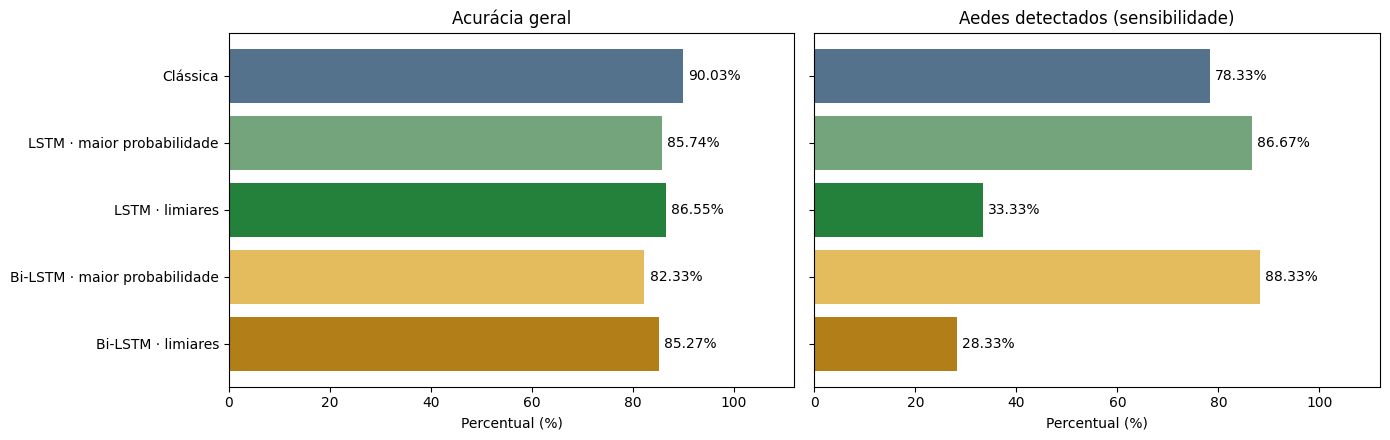

In [26]:
plot_rows = [("Clássica", NEURAL_REFERENCE["metrics"]["reference"])]
for row in NEURAL_REFERENCE["metrics"]["neural_models"]:
    name = "Bi-LSTM" if row["model"] == "bilstm" else "LSTM"
    rule = "maior probabilidade" if row["decision"] == "argmax" else "limiares"
    plot_rows.append((f"{name} · {rule}", row))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
names = [name for name, _ in plot_rows]
colors = ["#54728c", "#73a47b", "#24813b", "#e4bb5d", "#b27e17"]
for axis, key, title in zip(axes, ["accuracy", "aedes_recall"], ["Acurácia geral", "Aedes detectados (sensibilidade)"]):
    values = [100 * row[key] for _, row in plot_rows]
    bars = axis.barh(names, values, color=colors)
    axis.set(xlim=(0, 112), xlabel="Percentual (%)", title=title)
    axis.set_xticks([0, 20, 40, 60, 80, 100])
    for bar, value in zip(bars, values):
        axis.text(value + 1, bar.get_y() + bar.get_height()/2, f"{value:.2f}%", va="center")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

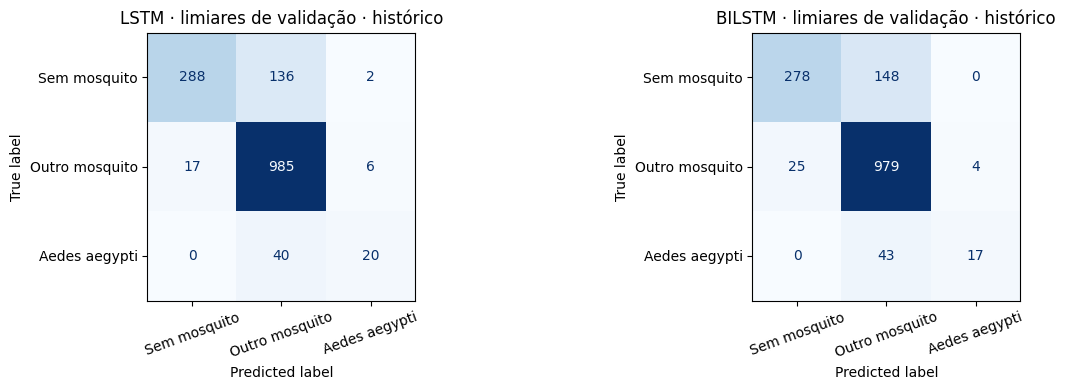

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, axis in zip(["lstm", "bilstm"], axes):
    score = next(row for row in NEURAL_REFERENCE["metrics"]["neural_models"]
                 if row["model"] == name and row["decision"] == "calibrated")
    ConfusionMatrixDisplay(np.asarray(score["confusion_matrix_raw"]), display_labels=labels).plot(
        ax=axis, cmap="Blues", values_format="d", colorbar=False)
    axis.set_title(f"{name.upper()} · limiares de validação · histórico")
    axis.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### Evolução do erro durante o treinamento

Estas são curvas reais da seleção interna do **contexto final histórico**, não médias de todas as dobras. A linha de treino mede perda por janela e a de validação mede perda por grupo; seus denominadores diferem. A linha vertical marca a época escolhida pela menor perda de validação:4 na LSTM e2 na Bi-LSTM. Não houve novo treinamento para produzir estas figuras.

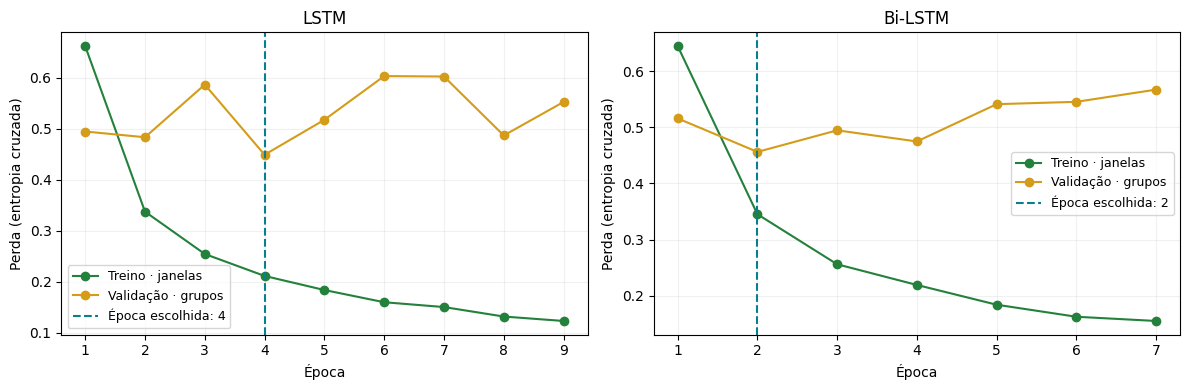

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, axis in zip(["lstm", "bilstm"], axes):
    history = pd.DataFrame(NEURAL_REFERENCE["final_training_histories"][name])
    best = next(row["best_epoch"] for row in NEURAL_REFERENCE["final_candidates"]
                if row["model"] == name)
    axis.plot(history.epoch, history.train_loss, marker="o", color="#24813b", label="Treino · janelas")
    axis.plot(history.epoch, history.validation_group_loss, marker="o", color="#d49c19", label="Validação · grupos")
    axis.axvline(best, linestyle="--", color="#087f8c", label=f"Época escolhida: {best}")
    axis.set(title="LSTM" if name == "lstm" else "Bi-LSTM", xlabel="Época", ylabel="Perda (entropia cruzada)")
    axis.set_xticks(history.epoch)
    axis.grid(alpha=.18)
    axis.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 10. Treinar LSTM e Bi-LSTM em uma nova rodada

O treino está desativado por padrão. Para executá-lo, habilite `RUN_NEURAL_TRAINING`. Se a cascata foi treinada nesta sessão, suas partições e métricas serão usadas; caso contrário, aponte `NEURAL_REFERENCE_RUN` para uma rodada clássica concluída com cinco dobras.

Entradas necessárias: `segments.csv.gz`, `partitions.csv.gz` e `event_level_metrics.json` da rodada clássica, mais `data/cache/reliability_2026_10_01/long_8k.npy`. Esse cache contém as janelas reais do manifesto, com7936 amostras por linha; índices e hashes precisam corresponder. Metadados sozinhos não substituem áudio. Os scripts de aquisição antigos não estão distribuídos neste repositório enxuto.

O programa extrai a sequência mel do cache de áudio e registra seus hashes. Uma pasta nova contém configurações, divisões, seleção interna, pesos, normalizadores e resultados das duas redes. Checkpoints históricos não são sobrescritos. Use `NEURAL_DEVICE="cpu"` se não houver PyTorch compatível com a GPU; o treino completo pode ser demorado.

In [29]:
NEURAL_RUN = None
if RUN_NEURAL_TRAINING:
    import torch
    from train_ternary_lstm import run as run_neural

    torch.set_num_threads(THREADS)
    device = torch.device(NEURAL_DEVICE if NEURAL_DEVICE != "auto"
                          else "cuda" if torch.cuda.is_available() else "cpu")
    reference_run = TRAINED_RUN if TRAINED_RUN is not None else Path(NEURAL_REFERENCE_RUN)
    if not reference_run.is_absolute():
        reference_run = ROOT / reference_run
    needed = [reference_run / name for name in
              ["segments.csv.gz", "partitions.csv.gz", "event_level_metrics.json"]]
    needed.append(ROOT / "data/cache/reliability_2026_10_01/long_8k.npy")
    missing = [str(path) for path in needed if not path.is_file()]
    if missing:
        raise FileNotFoundError("Prepare a rodada clássica e o cache de áudio antes de treinar:\n" + "\n".join(missing))
    run_id = datetime.now(timezone.utc).strftime("ternary_neural_notebook_%Y%m%dT%H%M%S%fZ")
    NEURAL_RUN = ROOT / "results" / run_id
    run_neural(NEURAL_RUN, reference_run, device)
    print("LSTM e Bi-LSTM treinadas e avaliadas em:", NEURAL_RUN)
elif EXISTING_NEURAL_RUN is not None:
    candidate = Path(EXISTING_NEURAL_RUN)
    candidate = candidate if candidate.is_absolute() else ROOT / candidate
    if (candidate / "complete.json").is_file():
        NEURAL_RUN = candidate
        print("Rodada local existente disponível, sem retreino:", NEURAL_RUN)
    else:
        print("Nenhuma rodada neural local. A comparação acima é a referência histórica publicada.")
else:
    print("Nenhum treino neural iniciado.")

Rodada local existente disponível, sem retreino: /home/lciarallo/Documentos/Git_projects/mosquito-wingbeat/results/ternary_lstm_2026_10_15


## 11. Ler os resultados de uma rodada neural local

Esta célula só mostra uma rodada efetivamente concluída. Se forem usados os pesos locais antigos, os resultados continuam sendo históricos. A verificação opcional reproduz todas as previsões OOF e confere partições, normalização, épocas e hashes; não altera os pesos nem os recibos anteriores.

In [30]:
if NEURAL_RUN is not None:
    completed = json.loads((NEURAL_RUN / "complete.json").read_text())
    if not completed.get("complete"):
        raise ValueError("A rodada neural ainda não foi concluída.")
    neural_metrics = json.loads((NEURAL_RUN / "metrics.json").read_text())
    display(comparison_table(neural_metrics))
    if VERIFY_NEURAL_RUN:
        import torch
        from verify_ternary_lstm import verify as verify_neural
        device = torch.device(NEURAL_DEVICE if NEURAL_DEVICE != "auto"
                              else "cuda" if torch.cuda.is_available() else "cpu")
        display(verify_neural(NEURAL_RUN, device))
else:
    print("Sem resultados de nova rodada. Consulte os números históricos da seção9.")

,Modelo e regra,Acurácia,Sensibilidade Aedes,FPR ruído → Aedes,FPR outro → Aedes
0,Clássica,90.03%,78.33%,0.00%,2.28%
1,LSTM · maior probabilidade,85.74%,86.67%,3.76%,3.97%
2,LSTM · limiares da validação,86.55%,33.33%,0.47%,0.60%
3,Bi-LSTM · maior probabilidade,82.33%,88.33%,4.93%,6.25%
4,Bi-LSTM · limiares da validação,85.27%,28.33%,0.00%,0.40%


## 12. Aplicar as duas redes a um WAV

Defina `AUDIO_PATH`. A rodada vem do treino acima ou de `EXISTING_NEURAL_RUN`, que exige pesos/normalizadores locais já concluídos. Um clone não baixa modelos automaticamente. Cada arquitetura usa seu próprio normalizador e limiares congelados, sem ajuste a partir desse WAV.

O trecho precisa ter pelo menos0,992s reais. A rede analisa as janelas completas; a cauda incompleta é descartada, sem repetir ou preencher o áudio. `NEURAL_MC_PASSES=100` ativa100 passagens de dropout como análise adicional de discordância; concordância não comprova acerto. A avaliação OOF principal é determinística.

In [31]:
if AUDIO_PATH is None:
    print("Defina AUDIO_PATH para aplicar LSTM e Bi-LSTM ao áudio.")
elif NEURAL_RUN is None:
    print("Configure uma rodada neural concluída ou execute o treino neural antes da aplicação.")
else:
    import torch
    from predict_ternary_lstm import predict as predict_neural
    torch.set_num_threads(THREADS)
    audio_path = Path(AUDIO_PATH).expanduser()
    audio_path = audio_path if audio_path.is_absolute() else ROOT / audio_path
    answers = []
    for architecture in ["lstm", "bilstm"]:
        answer = predict_neural(NEURAL_RUN, audio_path, name=architecture,
                                passes=NEURAL_MC_PASSES, device=NEURAL_DEVICE)
        answers.append({"Modelo": architecture.upper(), "Decisão": answer["decision"],
                        "Janelas reais": answer["windows"],
                        "Probabilidades [ruído, outro, Aedes]": answer["deterministic_probabilities"]})
    display(pd.DataFrame(answers))

Defina AUDIO_PATH para aplicar LSTM e Bi-LSTM ao áudio.


## 13. Interpretar e comunicar com responsabilidade

- `no_mosquito`: o modelo não encontrou evidência suficiente para as classes de mosquito avaliadas.
- `other_mosquito`: candidato a mosquito fora de *Aedes aegypti*; a classe agrega diferentes espécies.
- `aedes_aegypti`: candidato da classe, sujeito a falsos positivos observados no teste.
- `invalid_audio`: entrada inválida segundo as verificações de qualidade.

A avaliação é retrospectiva e limitada aos grupos e às fontes deste corpus. Os dados podem compartilhar indivíduos, locais ou condições de gravação. Uma gravação externa pequena também não substitui uma coleta independente. Antes de qualquer uso operacional, seriam necessárias novas gravações com indivíduos/sessões separados, rótulos biológicos confirmados, ruído sem mosquito e protocolo definido antes do teste.

## Arquivos de implementação usados pelo caderno

## Implementações clássicas e neurais

O notebook é o roteiro único de uso e ensino. Os módulos abaixo permanecem separados para que o congelamento por hash, as funções de treino e a inferência usem a mesma implementação auditável:

- `ternary_protocol.py`: leitura, filtragem, classes, grupos, auditoria PCM e regras temporais.
- `train_ternary_nested_models.py`: ajuste aninhado, modelos, calibração interna e congelamento.
- `evaluate_ternary_event_pipeline.py` e `ternary_reporting.py`: previsões externas e métricas por grupo.
- `predict_ternary.py`: aplicação em uma gravação nova.
- `aedes_classical.py` e `bioacoustic_invariance.py`: extração dos descritores acústicos.

O manifesto e o mapa de grupos ficam em `data/metadata/`. Áudios e cache de descritores são entradas locais e não são versionados neste repositório.

- `train_ternary_lstm.py`: treino LSTM/Bi-LSTM nas dobras clássicas, seleção interna e resultados OOF.
- `torres_lstm.py`: arquitetura recorrente e frontend mel reutilizados; o nome remete à técnica, não a um treino de infecção neste caderno.
- `predict_ternary_lstm.py`: aplicação dos pesos finais das duas redes.
- `verify_ternary_lstm.py`: reprodução das previsões e auditoria da rodada neural.
- `data/metadata/ternary_neural_reference.json`: resultados históricos compactos e hashes da origem.

Fontes de método: Torres et al. (2025), artigo fornecido para o projeto, e implementação arquivada no repositório do projeto. Os dados de infecção e o experimento de transferência posterior não foram acrescentados ao fluxo deste notebook.